# Мидтерм. Этап 1

## Отток клиентов телеком-компании


## Помощники


In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


# Этап 1

## 0. Карточка проекта


| Вопрос | Ответ |
|---|---|
| Датасет | [IBM Telco Customer Churn](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv) |
| Одна строка | Один клиент телеком-компании на момент сбора данных |
| Цель | `Churn`: ушёл ли клиент; Yes = 1, No = 0 |
| Задача | Бинарная классификация |
| Метрика | Accuracy; дополнительно на этапе 2 важно проверить recall для класса ухода |
| Кому и зачем | Команде удержания клиентов: заранее выявить клиентов с риском ухода и предложить помощь |


In [2]:
DATA_URL = ""   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = ""     # имя столбца-цели

DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
TARGET = "Churn"
print("Источник:", DATA_URL)
print("Целевой столбец:", TARGET)


Источник: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv
Целевой столбец: Churn


## 1. Первый взгляд


In [3]:
# загрузка, shape, head

raw = load_csv(DATA_URL)
print("Размер исходной таблицы:", raw.shape)
print("Первые 5 строк:")
print(raw.head().to_string(index=False))


Размер исходной таблицы: (7043, 21)
Первые 5 строк:
customerID gender  SeniorCitizen Partner Dependents  tenure PhoneService    MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies       Contract PaperlessBilling             PaymentMethod  MonthlyCharges TotalCharges Churn
7590-VHVEG Female              0     Yes         No       1           No No phone service             DSL             No          Yes               No          No          No              No Month-to-month              Yes          Electronic check           29.85        29.85    No
5575-GNVDE   Male              0      No         No      34          Yes               No             DSL            Yes           No              Yes          No          No              No       One year               No              Mailed check           56.95       1889.5    No
3668-QPYBK   Male              0      No         No       2          Yes               No       

In [4]:
# паспорт данных

print("Паспорт данных:")
print(passport(raw).to_string())


Паспорт данных:
                      тип  пропусков  доля, %  разных            пример
customerID            str          0      0.0    7043        7590-VHVEG
gender                str          0      0.0       2            Female
SeniorCitizen       int64          0      0.0       2                 0
Partner               str          0      0.0       2               Yes
Dependents            str          0      0.0       2                No
tenure              int64          0      0.0      73                 1
PhoneService          str          0      0.0       2                No
MultipleLines         str          0      0.0       3  No phone service
InternetService       str          0      0.0       3               DSL
OnlineSecurity        str          0      0.0       3                No
OnlineBackup          str          0      0.0       3               Yes
DeviceProtection      str          0      0.0       3                No
TechSupport           str          0      0.0   

In [5]:
# цель: распределение, при необходимости в числа 0 и 1

print("Распределение исходной цели:")
print(raw[TARGET].value_counts(dropna=False).to_string())
assert set(raw[TARGET].dropna().unique()) == {"Yes", "No"}, "Неожиданные метки цели"
target_numeric = raw[TARGET].map({"No": 0, "Yes": 1})
print("Доля ушедших клиентов, %:", round(100 * target_numeric.mean(), 2))
log("цель", "Churn: No → 0, Yes → 1; исходный raw не изменяем", len(raw))


Распределение исходной цели:
Churn
No     5174
Yes    1869
Доля ушедших клиентов, %: 26.54


**Вывод.** В файле 7043 строки и 21 столбец. Цель: 1869 ушедших (26,54%) и 5174 оставшихся. Явных `NaN` в паспорте нет, но `TotalCharges` имеет текстовый тип: нужно проверить пробелы и преобразовать значения в числа.


## 2. Дубли


In [6]:
# сколько дублей, какие они

print("Полных дублей:", int(raw.duplicated().sum()))
print("Повторов customerID:", int(raw.duplicated(subset=["customerID"]).sum()))
print("Примеры полных дублей:")
print(raw.loc[raw.duplicated(keep=False)].head().to_string(index=False))
print("Примеры повторов customerID:")
print(raw.loc[raw.duplicated("customerID", keep=False)].head().to_string(index=False))


Полных дублей: 0
Повторов customerID: 0
Примеры полных дублей:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []
Примеры повторов customerID:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []


In [7]:
# решение: df = ... ; log(...)

df = raw.copy().drop_duplicates().reset_index(drop=True)
print("После удаления полных дублей:", len(df))
assert not df["customerID"].duplicated().any(), "Повтор ID требует ручной проверки"
log("дубли", "Полных дублей и повторов ID нет; точные повторы удаляем, конфликтующие ID не удаляем автоматически", len(df))


После удаления полных дублей: 7043


**Вывод.** Полных дублей и повторов `customerID` не обнаружено. Одна строка соответствует одному клиенту. Автоматически удалять строки по повтору ID без проверки нельзя: одинаковый ID с разными данными потребует отдельного разбора.


## 3. Невозможные значения и скрытые пропуски


In [8]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        # "название правила": условие,
        "tenure меньше нуля": pd.to_numeric(d["tenure"], errors="coerce").lt(0),
        "MonthlyCharges не положителен": pd.to_numeric(d["MonthlyCharges"], errors="coerce").le(0),
        "TotalCharges меньше нуля": pd.to_numeric(d["TotalCharges"], errors="coerce").lt(0),
        "SeniorCitizen не 0 и не 1": ~d["SeniorCitizen"].isin([0, 1]),
    })

In [9]:
# сколько нарушений по каждому правилу, нарушители глазами

flags = check_rules(df)
print("Количество нарушений:")
print(flags.sum().to_string())
print("Строки с нарушениями:")
print(df.loc[flags.any(axis=1)].head(10).to_string(index=False))


Количество нарушений:
tenure меньше нуля               0
MonthlyCharges не положителен    0
TotalCharges меньше нуля         0
SeniorCitizen не 0 и не 1        0
Строки с нарушениями:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []


In [10]:
# скрытые пропуски: value_counts и describe

text_cols = df.select_dtypes(include=["object", "str", "string"]).columns
for col in text_cols:
    print(f"\n{col}: частоты, включая пустые и подозрительные значения")
    if col in ["customerID", "TotalCharges"]:
        print("уникальных:", df[col].nunique(), "пустых или пробельных:", df[col].astype("string").str.strip().eq("").sum())
        print(df[col].value_counts(dropna=False).head(5).to_string())
    else:
        print(df[col].value_counts(dropna=False).to_string())
print("\nЧисловые показатели:")
print(df.select_dtypes(include="number").describe().to_string())
print("Пробельные TotalCharges:", df["TotalCharges"].astype("string").str.strip().eq("").sum())



customerID: частоты, включая пустые и подозрительные значения
уникальных: 7043 пустых или пробельных: 0
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1

gender: частоты, включая пустые и подозрительные значения
gender
Male      3555
Female    3488

Partner: частоты, включая пустые и подозрительные значения
Partner
No     3641
Yes    3402

Dependents: частоты, включая пустые и подозрительные значения
Dependents
No     4933
Yes    2110

PhoneService: частоты, включая пустые и подозрительные значения
PhoneService
Yes    6361
No      682

MultipleLines: частоты, включая пустые и подозрительные значения
MultipleLines
No                  3390
Yes                 2971
No phone service     682

InternetService: частоты, включая пустые и подозрительные значения
InternetService
Fiber optic    3096
DSL            2421
No             1526

OnlineSecurity: частоты, включая пустые и подозрительные значения
OnlineSecurity
No                     3498
Yes    

In [11]:
# решения и журнал

assert not flags.any(axis=None), "Найденные нарушения нужно изучить вручную"
print("Правила пройдены. Подозрительные строки не удаляем автоматически.")
log("правила", "Проверены tenure ≥ 0, MonthlyCharges > 0, TotalCharges ≥ 0 и SeniorCitizen ∈ {0,1}; нарушений нет", len(df))
log("скрытые пропуски", "11 пустых TotalCharges — пропуски; No internet service / No phone service — смысловые категории, не NaN", len(df))


Правила пройдены. Подозрительные строки не удаляем автоматически.


**Вывод.** Четыре правила проверены, нарушений нет; пустой `TotalCharges` не принимается за отрицательное значение и разбирается отдельно. Найдено 11 пробельных значений. Категории `No internet service` и `No phone service` означают отсутствие соответствующей услуги, а не неизвестное значение.


## 4. Пропуски


In [12]:
# где пропуски и сколько

df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype("string").str.strip(), errors="coerce")
print("Пропуски после приведения TotalCharges к числу:")
print(df.isna().sum().loc[lambda s: s > 0].to_string())
print("Клиенты с пропуском:")
print(df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", TARGET]].to_string(index=False))


Пропуски после приведения TotalCharges к числу:
TotalCharges    11
Клиенты с пропуском:
customerID  tenure  MonthlyCharges  Churn
4472-LVYGI       0           52.55      0
3115-CZMZD       0           20.25      0
5709-LVOEQ       0           80.85      0
4367-NUYAO       0           25.75      0
1371-DWPAZ       0           56.05      0
7644-OMVMY       0           19.85      0
3213-VVOLG       0           25.35      0
2520-SGTTA       0           20.00      0
2923-ARZLG       0           19.70      0
4075-WKNIU       0           73.35      0
2775-SEFEE       0           61.90      0


In [13]:
# пропуск как информация: цель у строк с пропуском и без

for col in df.columns[df.isna().any()]:
    print(f"\nЦель при наличии и отсутствии {col}:")
    print(df.groupby(df[col].isna())[TARGET].agg(["size", "mean"]).to_string())



Цель при наличии и отсутствии TotalCharges:
              size      mean
TotalCharges                
False         7032  0.265785
True            11  0.000000


In [14]:
# заполнение и журнал

missing_total = df["TotalCharges"].isna()
assert (df.loc[missing_total, "tenure"] == 0).all(), "Пропуски не только у новых клиентов — нужно другое решение"
df["TotalCharges_missing"] = missing_total.astype(int)
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
print("Заполнено пропусков TotalCharges:", int(missing_total.sum()))
print("Сумма пропусков после заполнения:", int(df.isna().sum().sum()))
log("пропуски", "11 пустых TotalCharges у клиентов с tenure=0: сохранён флаг; 0 — допущение для новых клиентов, а не подтверждённая сумма", len(df))


Заполнено пропусков TotalCharges: 11
Сумма пропусков после заполнения: 0


**Решение по пропускам**


| Столбец | Пропусков | Смысл | Решение | Почему |
|---|---:|---|---|---|
| TotalCharges | 11 | Неизвестная сумма у клиентов с tenure = 0 | Флаг `TotalCharges_missing`, значение 0 | Ноль — рабочее допущение для новых клиентов, флаг сохраняет факт отсутствия исходного значения |

Для строк с пропуском доля Churn равна 0/11, без пропуска — около 26,58%; выборка из 11 строк слишком мала для надёжного вывода. Других пропусков в данных нет. Категории отсутствующей услуги не являются пропусками.


## 5. Типы и даты


In [15]:
# числа текстом

print("Типы после преобразования:")
print(df.dtypes.to_string())
print("Пример преобразованного TotalCharges:", df["TotalCharges"].head().tolist())
assert pd.api.types.is_numeric_dtype(df["TotalCharges"])
log("типы", "TotalCharges преобразован из строки в число; цель — целые 0/1", len(df))


Типы после преобразования:
customerID                  str
gender                      str
SeniorCitizen             int64
Partner                     str
Dependents                  str
tenure                    int64
PhoneService                str
MultipleLines               str
InternetService             str
OnlineSecurity              str
OnlineBackup                str
DeviceProtection            str
TechSupport                 str
StreamingTV                 str
StreamingMovies             str
Contract                    str
PaperlessBilling            str
PaymentMethod               str
MonthlyCharges          float64
TotalCharges            Float64
Churn                     int64
TotalCharges_missing      int64
Пример преобразованного TotalCharges: [29.85, 1889.5, 108.15, 1840.75, 151.65]


In [16]:
# даты

print("Столбцов с датами в исходном Telco нет; признаки из дат не создаются.")


Столбцов с датами в исходном Telco нет; признаки из дат не создаются.


**Вывод.** `TotalCharges` был текстом из-за пробельных строк и преобразован в число. `Churn` переведён из Yes/No в 1/0. Дат в исходной таблице нет.


## 6. Выбросы


In [17]:
# кандидаты в выбросы

outlier_stats = []
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((df[col] < lo) | (df[col] > hi)).sum())
    outlier_stats.append([col, q1, q3, lo, hi, count, df[col].max()])
outliers = pd.DataFrame(outlier_stats, columns=["столбец", "Q1", "Q3", "нижняя граница", "верхняя граница", "кандидатов", "максимум"])
print("Кандидаты по правилу 1,5 IQR:")
print(outliers.round(2).to_string(index=False))


Кандидаты по правилу 1,5 IQR:
       столбец     Q1      Q3  нижняя граница  верхняя граница  кандидатов  максимум
        tenure   9.00   55.00          -60.00           124.00           0     72.00
MonthlyCharges  35.50   89.85          -46.02           171.38           0    118.75
  TotalCharges 398.55 3786.60        -4683.52          8868.67           0   8684.80


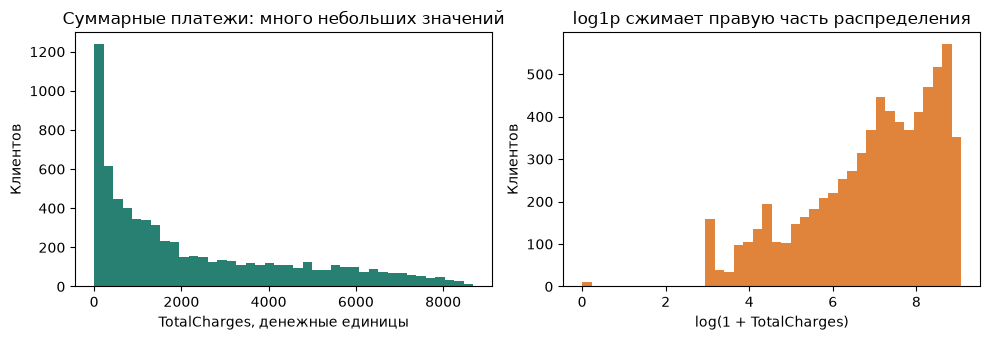

Кандидаты IQR отсутствуют; максимальные значения:
tenure              72.0
MonthlyCharges    118.75
TotalCharges      8684.8


In [18]:
# решения: удалить, обрезать, логарифм

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["TotalCharges"], bins=40, color=TEAL)
axes[0].set(title="Суммарные платежи: много небольших значений", xlabel="TotalCharges, денежные единицы", ylabel="Клиентов")
axes[1].hist(np.log1p(df["TotalCharges"]), bins=40, color=ORANGE)
axes[1].set(title="log1p сжимает правую часть распределения", xlabel="log(1 + TotalCharges)", ylabel="Клиентов")
plt.tight_layout(); plt.show()
print("Кандидаты IQR отсутствуют; максимальные значения:")
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].max().to_string())
log("выбросы", "IQR: кандидатов в tenure, MonthlyCharges, TotalCharges нет; допустимые крайние значения оставлены, log1p показан для сравнения", len(df))


**Вывод.** Для `tenure`, `MonthlyCharges` и `TotalCharges` правило 1,5 IQR не обнаружило кандидатов в выбросы. Крайние допустимые значения не удалены: высокая сумма платежей может соответствовать длительному сроку обслуживания. `log1p` показан для сравнения распределений, но в чистом файле исходная шкала сохранена.


## 7. Разведочный анализ данных


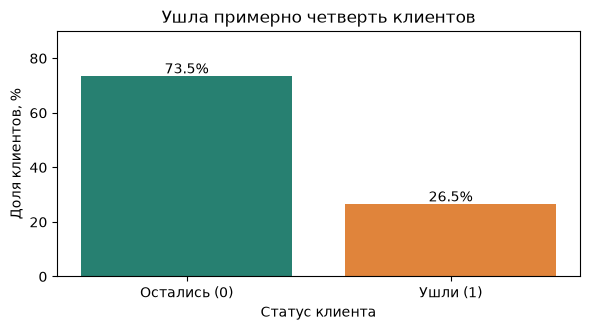

Число клиентов по классам: {0: 5174, 1: 1869}


In [19]:
# график 1

counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,3.4))
ax.bar(["Остались (0)", "Ушли (1)"], 100 * counts / len(df), color=[TEAL, ORANGE])
ax.set(title="Ушла примерно четверть клиентов", xlabel="Статус клиента", ylabel="Доля клиентов, %")
for i, v in enumerate(100 * counts / len(df)): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylim(0, 90); plt.tight_layout(); plt.show()
print("Число клиентов по классам:", counts.to_dict())


**Вывод.** В наборе 26,54% ушедших и 73,46% оставшихся клиентов. Из-за дисбаланса одного accuracy может быть недостаточно.


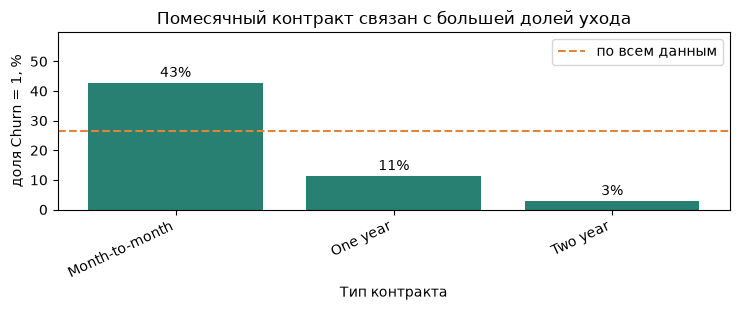

                 mean  size
Contract                   
Month-to-month  0.427  3875
One year        0.113  1473
Two year        0.028  1695


In [20]:
# график 2

contract_stats = target_plot(df, "Contract", TARGET, "Помесячный контракт связан с большей долей ухода", "Тип контракта")
print(contract_stats.to_string())


**Вывод.** При помесячном контракте доля ухода 42,71%, при годовом — 11,27%, при двухлетнем — 2,83%. Это связь, а не доказательство, что тип договора вызвал уход.


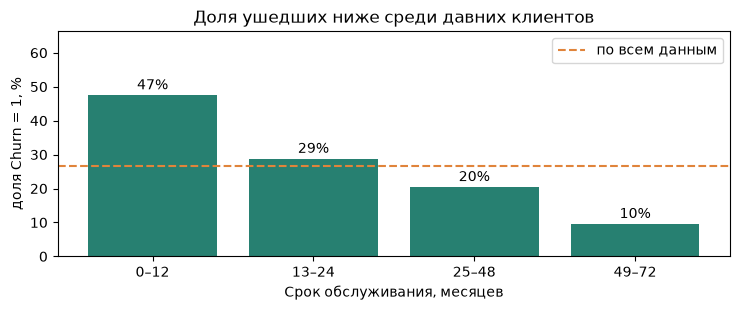

         mean  size
tenure             
0–12    0.474  2186
13–24   0.287  1024
25–48   0.204  1594
49–72   0.095  2239


In [21]:
# график 3

tenure_groups = pd.cut(df["tenure"], [-1,12,24,48,72], labels=["0–12", "13–24", "25–48", "49–72"])
tenure_stats = target_plot(df, tenure_groups, TARGET, "Доля ушедших ниже среди давних клиентов", "Срок обслуживания, месяцев")
print(tenure_stats.to_string())


**Вывод.** В группе 0–12 месяцев доля ухода около 47,4%, а в группе 49–72 месяца — около 9,5%. Это наблюдение по данным, а не доказательство причины.


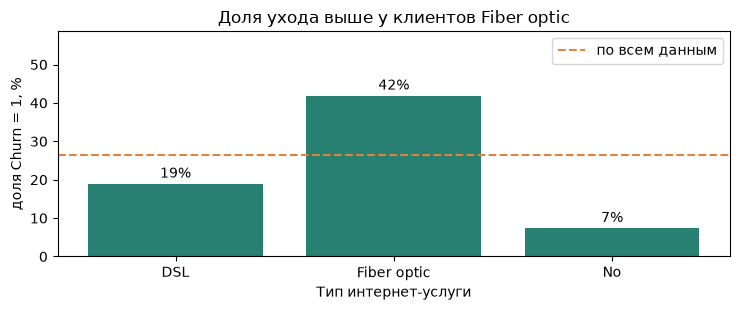

                  mean  size
InternetService             
DSL              0.190  2421
Fiber optic      0.419  3096
No               0.074  1526


In [22]:
# график 4

internet_stats = target_plot(df, "InternetService", TARGET, "Доля ухода выше у клиентов Fiber optic", "Тип интернет-услуги")
print(internet_stats.to_string())


**Вывод.** Доля ухода среди клиентов Fiber optic около 41,9%, среди DSL — 19,0%, без интернет-услуги — 7,4%. Группы могут различаться и по другим признакам.


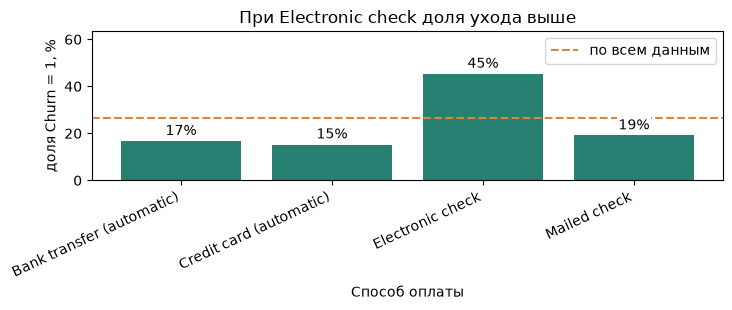

                            mean  size
PaymentMethod                         
Bank transfer (automatic)  0.167  1544
Credit card (automatic)    0.152  1522
Electronic check           0.453  2365
Mailed check               0.191  1612


In [23]:
# график 5

pay_stats = target_plot(df, "PaymentMethod", TARGET, "При Electronic check доля ухода выше", "Способ оплаты")
print(pay_stats.to_string())


**Вывод.** При Electronic check доля ухода около 45,3%, а при автоматической оплате банковским переводом — около 16,7%. Сам по себе график не доказывает влияние способа оплаты.


**Вывод.** Уходят 26,54% клиентов. Более высокая доля ухода наблюдается у клиентов с помесячным контрактом (42,71%), сроком 0–12 месяцев (47,44%), Fiber optic (41,89%) и Electronic check (45,29%). Это описательные связи; устойчивость и применимость признаков необходимо проверить на этапе 2 без утечки.


## 8. Функция очистки и журнал решений


In [24]:
def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()
    # ваши шаги из разделов 2-6
    required = {"customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"}
    assert required.issubset(d.columns), "Нет обязательных столбцов"
    d = d.drop_duplicates().reset_index(drop=True)
    assert not d["customerID"].duplicated().any(), "Повтор customerID требует проверки"
    assert d["Churn"].isin(["Yes", "No"]).all(), "Неизвестная или пропущенная цель"
    d["Churn"] = d["Churn"].map({"No": 0, "Yes": 1})
    for col in ["tenure", "MonthlyCharges", "SeniorCitizen"]:
        d[col] = pd.to_numeric(d[col], errors="raise")
    original_total = d["TotalCharges"].astype("string").str.strip()
    d["TotalCharges"] = pd.to_numeric(original_total, errors="coerce")
    assert (d["TotalCharges"].notna() | original_total.isna() | original_total.eq("")).all(), "Неожиданный текст в TotalCharges"
    assert not check_rules(d).any(axis=None), "Нарушены правила значений"
    missing = d["TotalCharges"].isna()
    assert (d.loc[missing, "tenure"] == 0).all(), "Пропуск у клиента с tenure > 0"
    d["TotalCharges_missing"] = missing.astype(int)
    d["TotalCharges"] = d["TotalCharges"].fillna(0.0)
    assert not d.isna().any().any(), "Есть необработанные пропуски"
    return d

In [25]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert

clean_df = clean(raw)
pd.testing.assert_frame_equal(clean_df, df)
assert len(clean_df) > len(raw) / 2
assert not clean_df.duplicated().any()
assert not clean_df["customerID"].duplicated().any()
assert clean_df[TARGET].isin([0, 1]).all()
assert clean_df.isna().sum().sum() == 0
assert not check_rules(clean_df).any(axis=None)
print("clean(raw) совпадает с пошаговой очисткой; все assert пройдены.")
print("Размер чистой таблицы:", clean_df.shape)
log("clean", "Функция clean воспроизводит пошаговую очистку; проверки пройдены", len(clean_df))


clean(raw) совпадает с пошаговой очисткой; все assert пройдены.
Размер чистой таблицы: (7043, 22)


In [26]:
# show_journal()

print("Журнал решений:")
print(show_journal().to_string())


Журнал решений:
                                                                                                                                         решение строк
цель                                                                                            Churn: No → 0, Yes → 1; исходный raw не изменяем  7043
дубли                                         Полных дублей и повторов ID нет; точные повторы удаляем, конфликтующие ID не удаляем автоматически  7043
правила                                        Проверены tenure ≥ 0, MonthlyCharges > 0, TotalCharges ≥ 0 и SeniorCitizen ∈ {0,1}; нарушений нет  7043
скрытые пропуски                         11 пустых TotalCharges — пропуски; No internet service / No phone service — смысловые категории, не NaN  7043
пропуски                11 пустых TotalCharges у клиентов с tenure=0: сохранён флаг; 0 — допущение для новых клиентов, а не подтверждённая сумма  7043
типы                                                                          

In [27]:
Path("data").mkdir(exist_ok=True)
# clean_df.to_csv("data/<имя>_clean.csv", index=False)

clean_path = Path("data/telco_clean.csv")
clean_df.to_csv(clean_path, index=False)
print("Сохранено:", clean_path, "байт:", clean_path.stat().st_size)
assert clean_path.stat().st_size < 25 * 1024 * 1024


Сохранено: data/telco_clean.csv байт: 977106


## 9. Самопроверка


In [28]:
# selfcheck(raw, clean_df, TARGET)

selfcheck(raw, clean_df, TARGET)


OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 22


**Этап 1 завершён.** Ноутбук и очищенные данные подготовлены к публикации в репозитории.


# Этап 2. Прогноз оттока клиентов

In [29]:
# ПОМОЩНИКИ ЭТАПА 2. Запустите после ячейки «Помощники» этапа 1.
import joblib
import sklearn
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder


def is_class(y):
    """Цель 0 и 1: классификация. Иначе регрессия."""
    return set(pd.Series(y).dropna().unique()) <= {0, 1}


def make_prep(num_cols, cat_cols=(), flag_cols=(), add_features=None, min_frequency=10, target_cols=(), y=None):
    """Вся подготовка одним объектом, как в части 5 практики занятия 12.

    num_cols: числа, заполняются медианой train и стандартизируются;
    flag_cols: флаги 0 и 1, идут как есть;
    cat_cols: категории, флаги через OneHotEncoder, редкие реже min_frequency в общий столбец;
    target_cols: категории с сотнями значений, кодирование по цели через TargetEncoder (нужен y);
    add_features: ваша функция признаков по одной строке, станет первым шагом.
    """
    branches = [(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(num_cols))]
    if flag_cols:
        branches.append(("passthrough", list(flag_cols)))
    if cat_cols:
        branches.append((OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                       sparse_output=False), list(cat_cols)))
    if target_cols:
        branches.append((make_target_encoder(y), list(target_cols)))
    steps = [FunctionTransformer(add_features)] if add_features is not None else []
    return make_pipeline(*steps, make_column_transformer(*branches))


def make_target_encoder(y):
    """TargetEncoder с одинаковым результатом на любой версии scikit-learn."""
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    folds = StratifiedKFold if is_class(y) else KFold
    if version >= (1, 9):
        return TargetEncoder(cv=folds(5, shuffle=True, random_state=0))
    return TargetEncoder(random_state=0)


def make_model(prep, y):
    """Подготовка и простая модель в одном Pipeline: логистическая регрессия для классов, линейная для чисел."""
    model = LogisticRegression(solver="newton-cholesky") if is_class(y) else LinearRegression()
    return make_pipeline(prep, model)


def make_dummy(y):
    """Пустышка: самый частый класс или медиана."""
    return DummyClassifier(strategy="most_frequent") if is_class(y) else DummyRegressor(strategy="median")


def cv_score(model, X, y):
    """Кросс-валидация на train: доля верных для классов, MAE для чисел."""
    if is_class(y):
        return cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    return -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error").mean()


def test_score(model, X_test, y_test):
    """Оценка на test: доля верных для классов, MAE для чисел. Вызывать один раз в конце."""
    prediction = model.predict(X_test)
    if is_class(y_test):
        return accuracy_score(y_test, prediction)
    return mean_absolute_error(y_test, prediction)


def ladder_plot(ladder, y, path=None):
    """График-лестница: пустышка первой ступенью. Заголовок-вывод считается сам."""
    names, values = list(ladder.index), list(ladder.values)
    if is_class(y):
        title = f"Модель лучше пустышки на {(max(values) - values[0]) * 100:.1f} процентного пункта"
        ylabel, fmt, low = "доля верных", "%.3f", 0.5 if min(values) > 0.5 else 0
    else:
        title = f"Модель ошибается на {(1 - min(values) / values[0]) * 100:.0f}% меньше пустышки"
        ylabel, fmt, low = "MAE, меньше лучше", "%.2f", 0
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    colors = [GRAY] + [TEAL] * (len(values) - 1)
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_ylim(low, max(values) * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(names) > 4:
        plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120)
    plt.show()


def write_requirements(path="requirements.txt"):
    """requirements.txt с версиями библиотек этой среды."""
    import matplotlib
    lines = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"scikit-learn=={sklearn.__version__}",
             f"matplotlib=={matplotlib.__version__}", f"joblib=={joblib.__version__}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


## 10. Признаки одного клиента

In [30]:
from features import add_features
from inspect import getsource
print(getsource(add_features))
print(add_features(clean_df.head(3))[["extra_count","new_customer","automatic_payment"]])

def add_features(data):
    """Признаки одного клиента, доступные до решения об уходе."""
    result = data.copy()
    extras = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
              "StreamingTV", "StreamingMovies"]
    result["extra_count"] = data[extras].eq("Yes").sum(axis=1)
    result["new_customer"] = data["tenure"].le(12).astype(int)
    result["automatic_payment"] = data["PaymentMethod"].isin(
        ["Bank transfer (automatic)", "Credit card (automatic)"]).astype(int)
    return result

   extra_count  new_customer  automatic_payment
0            1             1                  0
1            2             0                  0
2            2             1                  0


| Признак | Зачем |
|---|---|
| extra_count | Число подключённых дополнительных услуг характеризует использование пакета. |
| new_customer | Выделяет клиентов первого года обслуживания. |
| automatic_payment | Объединяет два способа автоматической оплаты. |

## 11. Подготовка чисел и категорий

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import recall_score
leaks = ["Churn", "customerID", "TotalCharges", "TotalCharges_missing"]
X, y = clean_df.drop(columns=leaks), clean_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
nums = ["tenure", "MonthlyCharges", "extra_count"]
flags = ["SeniorCitizen", "new_customer", "automatic_payment"]
cats = X_train.select_dtypes(exclude="number").columns.tolist()
def full_model(freq, extra_nums=()):
    prep = make_prep(nums + list(extra_nums), cats, flags, add_features, min_frequency=freq)
    return make_model(prep, y_train)
prep = make_prep(nums, cats, flags, add_features, min_frequency=10)
Z = prep.fit_transform(X_train, y_train)
assert np.issubdtype(Z.dtype, np.number) and np.isfinite(Z).all()
print("Train / test:", len(X_train), len(X_test))
print("Уровни категорий на train:", X_train[cats].nunique().to_dict())
print("При пороге 10:", Z.shape[1], "числовых признаков, пропусков:", np.isnan(Z).sum())

Train / test: 5634 1409
Уровни категорий на train: {'gender': 2, 'Partner': 2, 'Dependents': 2, 'PhoneService': 2, 'MultipleLines': 3, 'InternetService': 3, 'OnlineSecurity': 3, 'OnlineBackup': 3, 'DeviceProtection': 3, 'TechSupport': 3, 'StreamingTV': 3, 'StreamingMovies': 3, 'Contract': 3, 'PaperlessBilling': 2, 'PaymentMethod': 4}
При пороге 10: 47 числовых признаков, пропусков: 0


Порог редкости подбирается на пяти обучающих фолдах. Категориальные поля имеют мало уровней, поэтому для них достаточно OneHotEncoder.

## 12. Проверка утечки

Прогноз строим до решения клиента об уходе. Для применения нужен снимок тарифа и услуг на этот момент.

| Столбец | Когда известен | Решение |
|---|---|---|
| Churn | После ухода | Только цель |
| customerID | При регистрации | Исключён как идентификатор |
| TotalCharges и флаг пропуска | После начислений, точная дата среза неизвестна | Исключены из рабочего прогноза, проверяем влияние на train |
| tenure, MonthlyCharges, договор и услуги | При обслуживании | Используем значения на дату прогноза |

In [32]:
suspects = ["TotalCharges", "TotalCharges_missing"]
audit_X = X_train.join(clean_df[suspects])
honest = cv_score(full_model(10), X_train, y_train)
suspect_score = cv_score(full_model(10, suspects), audit_X, y_train)
print(f"CV без накопленных платежей: {honest:.2%}; с ними: {suspect_score:.2%}")
print("Разница в accuracy сама по себе не устанавливает дату доступности поля.")

CV без накопленных платежей: 80.64%; с ними: 80.69%
Разница в accuracy сама по себе не устанавливает дату доступности поля.


## 13. Baseline и итоговый прогноз

{'logisticregression__C': 1.0, 'pipeline__columntransformer__onehotencoder__min_frequency': 10}
Пустышка        0.7346
Три признака    0.7893
Полная          0.8064
dtype: float64


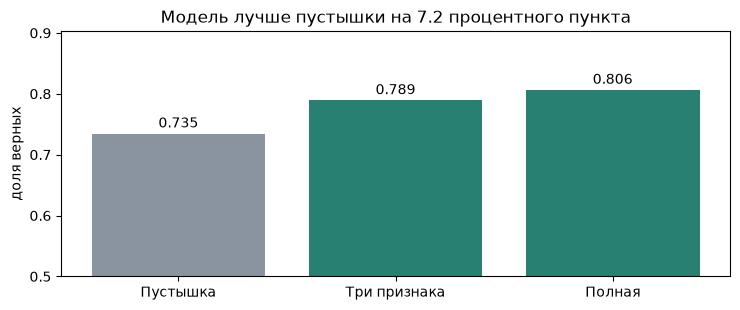

In [33]:
simple = make_model(make_prep(["tenure", "MonthlyCharges"], ["Contract"]), y_train)
search = GridSearchCV(full_model(10), {
    "pipeline__columntransformer__onehotencoder__min_frequency": [10, 0.1],
    "logisticregression__C": [0.1, 1.0]}, cv=5, scoring="accuracy", error_score="raise")
search.fit(X_train, y_train)
final_model = search.best_estimator_
dummy = make_dummy(y_train).fit(X_train, y_train)
ladder = pd.Series({"Пустышка": cv_score(dummy, X_train, y_train),
                    "Три признака": cv_score(simple, X_train, y_train),
                    "Полная": search.best_score_})
print(search.best_params_)
print(ladder.round(4))
ladder_plot(ladder, y_train, "figures/baseline.png")

In [34]:
pred = final_model.predict(X_test)
acc = accuracy_score(y_test, pred)
base = test_score(dummy, X_test, y_test)
rec = recall_score(y_test, pred)
gain = 100 * (acc - base)
print(f"Test: пустышка {base:.2%}, модель {acc:.2%}, разница {gain:+.2f} п.п.; recall ухода {rec:.2%}")

Test: пустышка 73.46%, модель 79.84%, разница +6.39 п.п.; recall ухода 51.07%


In [35]:
Path("model").mkdir(exist_ok=True)
joblib.dump(final_model, "model/telco.joblib")
loaded = joblib.load("model/telco.joblib")
example = X_train.iloc[[0]].copy()
example["PaymentMethod"] = "New payment method"
example["MonthlyCharges"] = np.nan
assert np.allclose(loaded.predict_proba(example), final_model.predict_proba(example))
print("Пример клиента с новым способом оплаты и неизвестной ценой. Вероятность ухода:",
      round(loaded.predict_proba(example)[0, 1], 3))

Пример клиента с новым способом оплаты и неизвестной ценой. Вероятность ухода: 0.229


## 14. Выводы

In [36]:
findings = [
    "Из 7043 клиентов ушли 1869 (26,54%).",
    "При помесячном контракте доля ухода 42,71%, при двухлетнем — 2,83%.",
    f"На test accuracy модели {acc:.2%}, выигрыш над пустышкой {gain:.2f} п.п.",
    f"Модель выявила {rec:.2%} ушедших. Следующая проверка — на клиентах более позднего периода."]
print("\n".join(findings))

Из 7043 клиентов ушли 1869 (26,54%).
При помесячном контракте доля ухода 42,71%, при двухлетнем — 2,83%.
На test accuracy модели 79.84%, выигрыш над пустышкой 6.39 п.п.
Модель выявила 51.07% ушедших. Следующая проверка — на клиентах более позднего периода.


## 15. README

In [37]:
readme = f"""# Отток клиентов Telco

Цель — предсказать уход клиента до его решения о расторжении договора. Одна строка соответствует одному клиенту. Использован учебный набор [IBM Telco Customer Churn]({DATA_URL}). Класс 1 означает уход.

## Данные и журнал решений

{chr(10).join("- " + str(v["решение"]) for v in journal.values())}

## Наблюдения и выводы

{chr(10).join("- " + line for line in findings)}

## Признаки и утечка

Модель учитывает число дополнительных услуг, первый год обслуживания и автоматическую оплату. Уникальный номер и целевая метка исключены из входов. Для накопленного платежа дата доступности неизвестна. Accuracy на обучающих фолдах без этого поля и флага пропуска составила {honest:.2%}, с ними {suspect_score:.2%}. Рабочая модель использует только признаки, доступные на момент прогноза.

## Сравнение моделей

Стратифицированное деление 80/20. На train подготовка обучалась заново в каждом из пяти фолдов. Варианты порога редкости и регуляризации сравнивались по accuracy. Отложенная выборка использована после выбора настроек.

| Модель | CV accuracy | Test accuracy |
|---|---:|---:|
| Пустышка | {ladder.iloc[0]:.2%} | {base:.2%} |
| Три признака | {ladder.iloc[1]:.2%} | — |
| Полная | {ladder.iloc[2]:.2%} | {acc:.2%} |

![Сравнение моделей](figures/baseline.png)

## Как запустить

Из корня проекта выполните `python -m pip install -r requirements.txt`, затем откройте `project.ipynb` в Jupyter и выполните все ячейки. Исходный CSV находится в `project_data/raw.csv`, очищенный — в `data/telco_clean.csv`. Модель загружается из корня проекта командой `joblib.load("model/telco.joblib")` после `import joblib`. Модуль `features.py` нужен для загрузки и построения признаков.
"""
Path("README.md").write_text(readme, encoding="utf-8")
print("README.md сохранён")

README.md сохранён


## 16. Воспроизводимость

In [38]:
write_requirements()
with Path("requirements.txt").open("a") as f:
    f.write("jupyterlab>=4,<5\n")
assert all(Path(p).is_file() for p in ["data/telco_clean.csv", "figures/baseline.png", "features.py", "model/telco.joblib", "README.md"])
print("Проверки пройдены.")

pandas==3.0.5
numpy==2.5.2
scikit-learn==1.9.0
matplotlib==3.11.1
joblib==1.6.0
Проверки пройдены.
